Selecciona el archivo cat_parametros.csv


Saving cat_parametros.csv to cat_parametros (5).csv

========== INSPECCION INICIAL ==========
Dimensiones originales: (38, 4)

Primeras cinco filas:


,id_parameter,cve_param,nom_param,unidades_param
0,1,O3,Ozono,1
1,2,NO2,Dióxido de nitrógeno,1
2,3,NO,Óxido nítrico,1
3,4,NOx,Óxidos de nitrógeno,1
4,5,CO,Monóxido de carbono,15



Informacion general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38 entries, 0 to 37
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id_parameter    38 non-null     int64 
 1   cve_param       38 non-null     object
 2   nom_param       38 non-null     object
 3   unidades_param  38 non-null     object
dtypes: int64(1), object(3)
memory usage: 1.3+ KB

Columnas:
['id_parameter', 'cve_param', 'nom_param', 'unidades_param']

========== VALORES FALTANTES ==========


,Cantidad,Porcentaje
id_parameter,0,0.0
cve_param,0,0.0
nom_param,0,0.0
unidades_param,0,0.0


...

,count,mean,std,min,25%,50%,75%,max
id_parameter,38.0,20.921053,11.849009,1.0,10.25,21.5,30.75,40.0



Resumen de variables categoricas:


,count,unique,top,freq
cve_param,38,38,O3,1
nom_param,38,38,Ozono,1
unidades_param,38,15,"13,14",10



Cantidad de parametros diferentes:
38

Cantidad de nombres diferentes:
38

Cantidad de codigos de unidad diferentes:
15

========== CATALOGO DE PARAMETROS ==========


,id_parameter,cve_param,nom_param,unidades_param
0,1,O3,Ozono,1
1,2,NO2,Dióxido de nitrógeno,1
2,3,NO,Óxido nítrico,1
3,4,NOx,Óxidos de nitrógeno,1
4,5,CO,Monóxido de carbono,15
5,6,SO2,Dióxido de azufre,1
6,7,PM10,Partículas menores a 10 micrómetros,2
7,8,PM2.5,Partículas menores a 2.5 micrómetros,2
8,9,PMco,Partículas coarse,2
9,10,BEN,Benceno,1


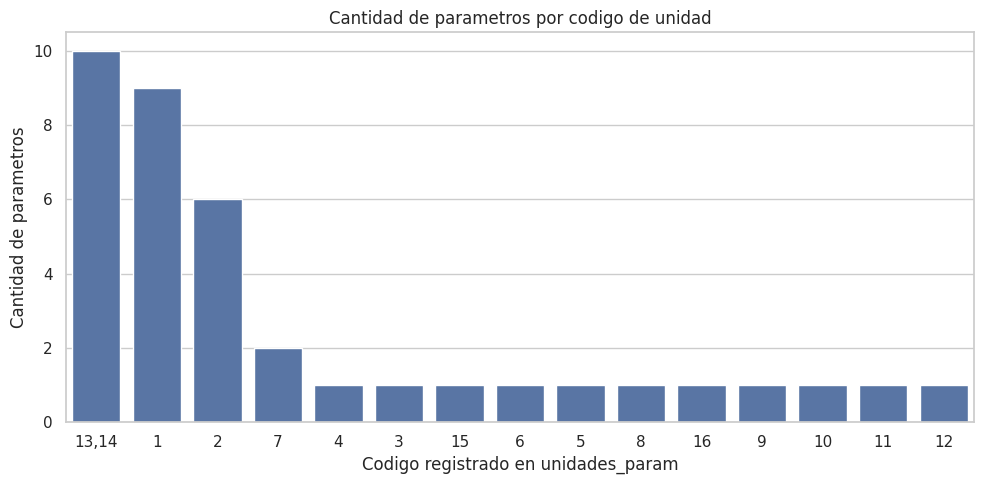

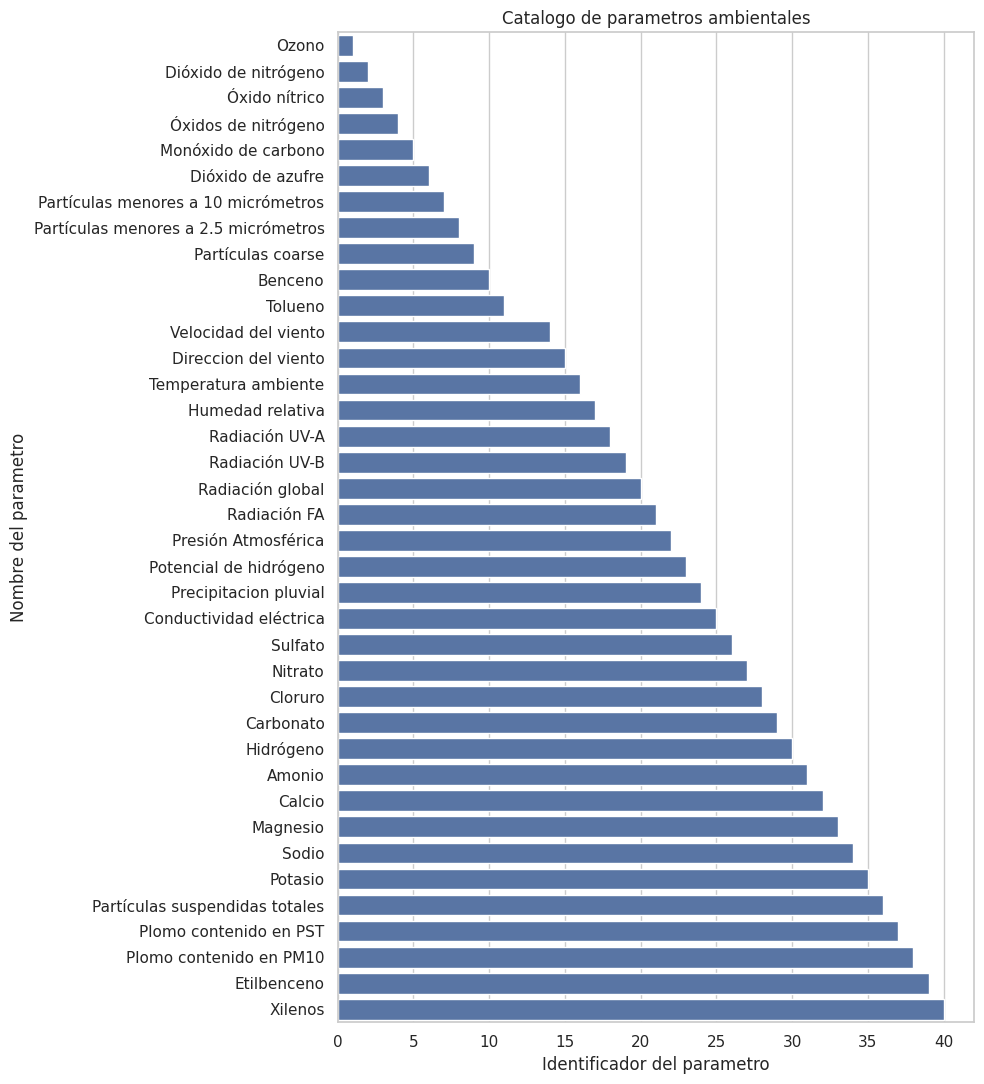


========== CORRELACION ==========
No hay suficientes variables numericas con variacion para calcular una correlacion util.

Archivo limpio generado: cat_parametros_limpio.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Analisis exploratorio terminado.


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from IPython.display import display

sns.set_theme(style="whitegrid")
# 1. CARGAR EL ARCHIVO
print("Selecciona el archivo cat_parametros.csv")
archivos = files.upload()
cat_parametros = next(iter(archivos))

# El archivo tiene una fila de titulo antes de los encabezados.
df_original = pd.read_csv(
    cat_parametros,
    encoding="latin1",
    skiprows=1)
print("\n========== INSPECCION INICIAL ==========")
print("Dimensiones originales:", df_original.shape)
print("\nPrimeras cinco filas:")
display(df_original.head())
print("\nInformacion general:")
df_original.info()
print("\nColumnas:")
print(df_original.columns.tolist())
# 2. LIMPIEZA BASICA
df = df_original.copy()
# Limpiar espacios de los nombres de columnas
df.columns = df.columns.str.strip()
# Limpiar espacios en columnas de texto
for columna in df.select_dtypes(include="object").columns:
    df[columna] = df[columna].str.strip()
# Convertir identificador a numero
df["id_parameter"] = pd.to_numeric(df["id_parameter"], errors="coerce")
# Revisar datos faltantes
print("\n========== VALORES FALTANTES ==========")
faltantes = pd.DataFrame({
    "Cantidad": df.isna().sum(),
    "Porcentaje": (df.isna().mean() * 100).round(2)
})
display(faltantes)
# Revisar filas duplicadas
print("Filas duplicadas:", df.duplicated().sum())
# Eliminar duplicados exactos, si existen
df = df.drop_duplicates().copy()
# Revisar claves repetidas
print("\nClaves de parametro repetidas:")
display(
    df[df["cve_param"].duplicated(keep=False)]
    .sort_values("cve_param"))
# No eliminamos registros solo porque tengan claves
print("\nDimensiones antes:", df_original.shape)
print("Dimensiones despues:", df.shape)
# 3. ESTADISTICA DESCRIPTIVA
print("\n========== ESTADISTICA DESCRIPTIVA ==========")
print("\nResumen de variables numericas:")
display(df.describe().T)
print("\nResumen de variables categoricas:")
display(df.describe(include="object").T)
print("\nCantidad de parametros diferentes:")
print(df["cve_param"].nunique())
print("\nCantidad de nombres diferentes:")
print(df["nom_param"].nunique())
print("\nCantidad de codigos de unidad diferentes:")
print(df["unidades_param"].nunique())
# 4. TABLA DEL CATALOGO
print("\n========== CATALOGO DE PARAMETROS ==========")
display(
    df[[
        "id_parameter",
        "cve_param",
        "nom_param",
        "unidades_param"
    ]].sort_values("id_parameter"))
# 5. GRAFICA 1: PARAMETROS POR CODIGO DE UNIDAD
# Los codigos se muestran como categorias, no como magnitudes.
conteo_unidades = (
    df["unidades_param"]
    .astype(str)
    .value_counts()
    .sort_values(ascending=False))
plt.figure(figsize=(10, 5))
sns.barplot(
    x=conteo_unidades.index,
    y=conteo_unidades.values)
plt.title("Cantidad de parametros por codigo de unidad")
plt.xlabel("Codigo registrado en unidades_param")
plt.ylabel("Cantidad de parametros")
plt.tight_layout()
plt.show()
# 6. GRAFICA 2: LISTADO VISUAL DE PARAMETROS
df_grafica = df.sort_values("id_parameter")

plt.figure(figsize=(10, 11))
sns.barplot(
    data=df_grafica,
    x="id_parameter",
    y="nom_param",
    orient="h")
plt.title("Catalogo de parametros ambientales")
plt.xlabel("Identificador del parametro")
plt.ylabel("Nombre del parametro")
plt.tight_layout()
plt.show()
# 7. MATRIZ DE CORRELACION
# Solo se calcula si existen al menos dos columnas
numericas = df.select_dtypes(include=np.number)
numericas = numericas.loc[
    :, numericas.nunique(dropna=True) > 1]
print("\n========== CORRELACION ==========")
if numericas.shape[1] >= 2:
    correlacion = numericas.corr()
    display(correlacion)
    plt.figure(figsize=(7, 5))
    sns.heatmap(
        correlacion,
        annot=True,
        cmap="coolwarm",
        vmin=-1,
        vmax=1)
    plt.title("Correlacion entre variables numericas")
    plt.tight_layout()
    plt.show()
else:
    print(
        "No hay suficientes variables numericas "
        "con variacion para calcular una correlacion util.")
# 8. EXPORTAR EL CATALOGO LIMPIO
archivo_salida = "cat_parametros_limpio.csv"
df.to_csv(archivo_salida, index=False, encoding="utf-8-sig")
print("\nArchivo limpio generado:", archivo_salida)
files.download(archivo_salida)
print("\nAnalisis exploratorio terminado.")

